# Hydro, Solar, Biomass, Wind and Geothermal Energy in the Midwestern U.S. Region
## Review 1: Time-Series Analysis (Trend, Seasonality, Stationarity, ACF / PACF)

This project analyses how electricity generation from **hydro, solar, biomass, wind and geothermal** sources changes over time in the
**Midwestern U.S. Census region**. It covers 12 states: Illinois, Indiana, Michigan, Ohio and Wisconsin (East North Central) and
Iowa, Kansas, Minnesota, Missouri, Nebraska, North Dakota and South Dakota (West North Central).
The research question covers hydro, solar, biomass, wind and geothermal.

The analysis focuses on:
* Trend
* Seasonality
* Stationarity
* Autocorrelation
* Partial autocorrelation

Each resource is analysed separately, because each one depends on a different natural driver (rainfall, sunlight, fuel supply).

## 1. Research Problem / Question

**Research Question**

How do hydro, solar, biomass and geothermal electricity generation vary over time in the Midwestern U.S. region, and what specific
trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

**Objective**

To study the temporal behaviour of each renewable resource in the Midwest by examining its trend, seasonality, stationarity,
autocorrelation and partial autocorrelation. Together these determine which forecasting models are suitable in Review 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

## 2. Dataset Understanding

The dataset is the **U.S. Energy Information Administration (EIA)** monthly net electricity generation by source, for every U.S. state
from January 2001 onwards.

| Variable | Description |
|---|---|
| month | First day of the month of the observation |
| census_region | U.S. Census region (Northeast, Midwest, South, West) |
| census_division | U.S. Census division (9 divisions) |
| hydro, wind, solar, biomass, geothermal | Net generation from each source, in **thousand MWh (= GWh)** |
| total_renewable | Sum of the five renewable sources (GWh) |
| total_generation | Net generation from all sources, renewable and non-renewable (GWh) |
| renewable_share_pct | total_renewable / total_generation × 100 |

The observations are recorded at a **monthly** frequency.

In [2]:
DATA_PATH = "usa_state_renewable_monthly_2001_2026.csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (15657, 11)


,month,census_region,census_division,hydro,wind,solar,biomass,geothermal,total_renewable,total_generation,renewable_share_pct
0,2001-01-01,West,Pacific,104.549,0.087,0.000,0.000,0.000,104.636,590.145,17.730
1,2001-02-01,West,Pacific,90.111,0.074,0.000,0.000,0.000,90.185,546.167,16.510
2,2001-03-01,West,Pacific,99.843,0.081,0.000,0.000,0.000,99.924,587.115,17.020
3,2001-04-01,West,Pacific,84.615,0.071,0.000,0.000,0.000,84.686,488.698,17.330
4,2001-05-01,West,Pacific,85.130,0.069,0.000,0.000,0.000,85.199,484.687,17.580


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15657 entries, 0 to 15656
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                15657 non-null  datetime64[ns]
 1   census_region        15657 non-null  object        
 2   census_division      15657 non-null  object        
 3   hydro                15657 non-null  float64       
 4   wind                 15657 non-null  float64       
 5   solar                15657 non-null  float64       
 6   biomass              15657 non-null  float64       
 7   geothermal           15657 non-null  float64       
 8   total_renewable      15657 non-null  float64       
 9   total_generation     15657 non-null  float64       
 10  renewable_share_pct  15642 non-null  float64       
dtypes: datetime64[ns](1), float64(8), object(2)
memory usage: 1.3+ MB


In [4]:
print("Census regions :", df["census_region"].unique())
print("Census divisions:", df["census_division"].nunique())
print("\nTime range:")
print("Start:", df["month"].min().date())
print("End  :", df["month"].max().date())
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Census regions : ['West' 'South' 'Northeast' 'Midwest']
Census divisions: 9

Time range:
Start: 2001-01-01
End  : 2026-07-01

Missing values in each column:
month                   0
census_region           0
census_division         0
hydro                   0
wind                    0
solar                   0
biomass                 0
geothermal              0
total_renewable         0
total_generation        0
renewable_share_pct    15
dtype: int64

Duplicate rows: 0


### Selecting the Midwestern region

For this study, only rows with `census_region == "Midwest"` are used. Each month has one row per Midwestern state, so the rows are
**added together** to give one monthly total per resource for the whole region.

In [4]:
region_df = df[df["census_region"] == "Midwest"].copy()

print("Midwestern rows:", region_df.shape)
print("Divisions in the Midwest:", region_df["census_division"].unique())
print("Rows (states) per month:", region_df.groupby("month").size().unique())

region = (
    region_df
    .groupby("month")[["hydro", "solar", "biomass", "geothermal", "wind"]]
    .sum()
)
print("\nMonthly regional series:", region.shape)
region.head()

Midwestern rows: (3684, 11)
Divisions in the Midwest: ['West North Central' 'East North Central']
Rows (states) per month: [12]

Monthly regional series: (307, 5)


,hydro,solar,biomass,geothermal,wind
month,,,,,
2001-01-01,1045.535,0.000,431.773,0.000,134.570
2001-02-01,1002.244,0.000,377.186,0.000,109.990
2001-03-01,1150.050,0.000,420.238,0.000,108.569
2001-04-01,985.651,0.000,406.616,0.000,150.812
2001-05-01,1003.070,0.000,405.594,0.000,125.709


In [5]:
region.describe()

,hydro,solar,biomass,geothermal,wind
count,307.000,307.000,307.000,307.000,307.000
mean,1290.662,381.051,552.611,0.000,6277.193
std,308.241,948.709,105.138,0.000,5825.660
min,681.270,0.000,316.106,0.000,78.287
25%,1073.893,0.000,458.563,0.000,746.505
50%,1267.102,11.839,551.017,0.000,4911.042
75%,1445.229,220.471,654.640,0.000,9966.570
max,2473.126,6301.997,761.019,0.000,21243.116


In [6]:
time_difference = region.index.to_series().diff()
print("Most common time intervals between observations:")
print(time_difference.value_counts().head())

full_range = pd.date_range(region.index.min(), region.index.max(), freq="MS")
print("\nMissing months:", len(full_range.difference(region.index)))

Most common time intervals between observations:
month
31 days    178
30 days    102
28 days     20
29 days      6
Name: count, dtype: int64

Missing months: 0


In [7]:
# How many months is each resource exactly zero?
print("Months with zero generation:")
print((region == 0).sum())
print("\nTotal geothermal generation in the Midwest, 2001-2026:", region["geothermal"].sum(), "GWh")

Months with zero generation:
hydro           0
solar         107
biomass         0
geothermal    307
wind            0
dtype: int64

Total geothermal generation in the Midwest, 2001-2026: 0.0 GWh


**Geothermal: no data to analyse**

Geothermal generation is **0 GWh in all 307 months** (Jan 2001 – Jul 2026), in every Midwestern state. The Midwest has no utility-scale
geothermal power plants, so geothermal is reported here and **excluded from the time-series modelling**. Its forecast is simply 0 GWh.

For context, **wind** (shown in the table above) is by far the Midwest's largest renewable source, averaging 6,277 GWh per month against 1,291 GWh for hydro.
It is outside the scope of this research question, so it is not modelled.

In [8]:
# When does solar become a measurable series?
print(region["solar"].loc["2009-06-01":"2012-06-01"].round(1).to_string())

month
2009-06-01   0.000
2009-07-01   0.000
2009-08-01   0.000
2009-09-01   0.000
2009-10-01   0.000
2009-11-01   0.000
2009-12-01   0.000
2010-01-01   0.100
2010-02-01   0.400
2010-03-01   1.100
2010-04-01   2.700
2010-05-01   3.700
2010-06-01   4.200
2010-07-01   3.900
2010-08-01   3.700
2010-09-01   3.100
2010-10-01   1.700
2010-11-01   1.500
2010-12-01   0.800
2011-01-01   0.600
2011-02-01   1.600
2011-03-01   2.200
2011-04-01   3.000
2011-05-01   3.500
2011-06-01   4.100
2011-07-01   3.500
2011-08-01   3.700
2011-09-01   2.700
2011-10-01   2.200
2011-11-01   1.300
2011-12-01   1.200
2012-01-01   1.200
2012-02-01   2.000
2012-03-01   3.700
2012-04-01   5.300
2012-05-01   7.900
2012-06-01   8.400


**Choosing the start of the solar series**

Midwestern solar output is **exactly zero until December 2009** (107 zero months). It stays below about 4 GWh/month through 2011, and some months
fall below 1 GWh (Jan 2010: 0.1 GWh; Jan 2011: 0.6 GWh). From **January 2012** onwards, every month is at least 1.2 GWh and the seasonal cycle is clear.
Solar is therefore analysed from **Jan 2012 (175 monthly observations)**. Earlier values are too small to carry a usable pattern, and the zeros make a log transform impossible.

## 3. Data Preparation

* The index is converted to a monthly datetime index with frequency `MS` (month start).
* **Geothermal is removed from the modelling**, because it is identically zero.
* **Solar** is analysed from January 2012 onwards.
* Hydro, wind and biomass use the full period, Jan 2001 – Jul 2026.

In [9]:
region = region.asfreq("MS")

RESOURCES = ["hydro", "solar", "biomass", "wind"]
SOLAR_START = "2012-01-01"

series = {
    "hydro":   region["hydro"],
    "solar":   region["solar"].loc[SOLAR_START:],
    "biomass": region["biomass"],
    "wind": region["wind"]
}

for r in RESOURCES:
    print(f"{r:8s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}  ->  {len(series[r])} monthly observations")

hydro   : Jan 2001 - Jul 2026  ->  307 monthly observations
solar   : Jan 2012 - Jul 2026  ->  175 monthly observations
biomass : Jan 2001 - Jul 2026  ->  307 monthly observations
wind    : Jan 2001 - Jul 2026  ->  307 monthly observations


## 4. Time-Series Visualization

The plots below show how generation from each resource changes over time in the Midwestern region.

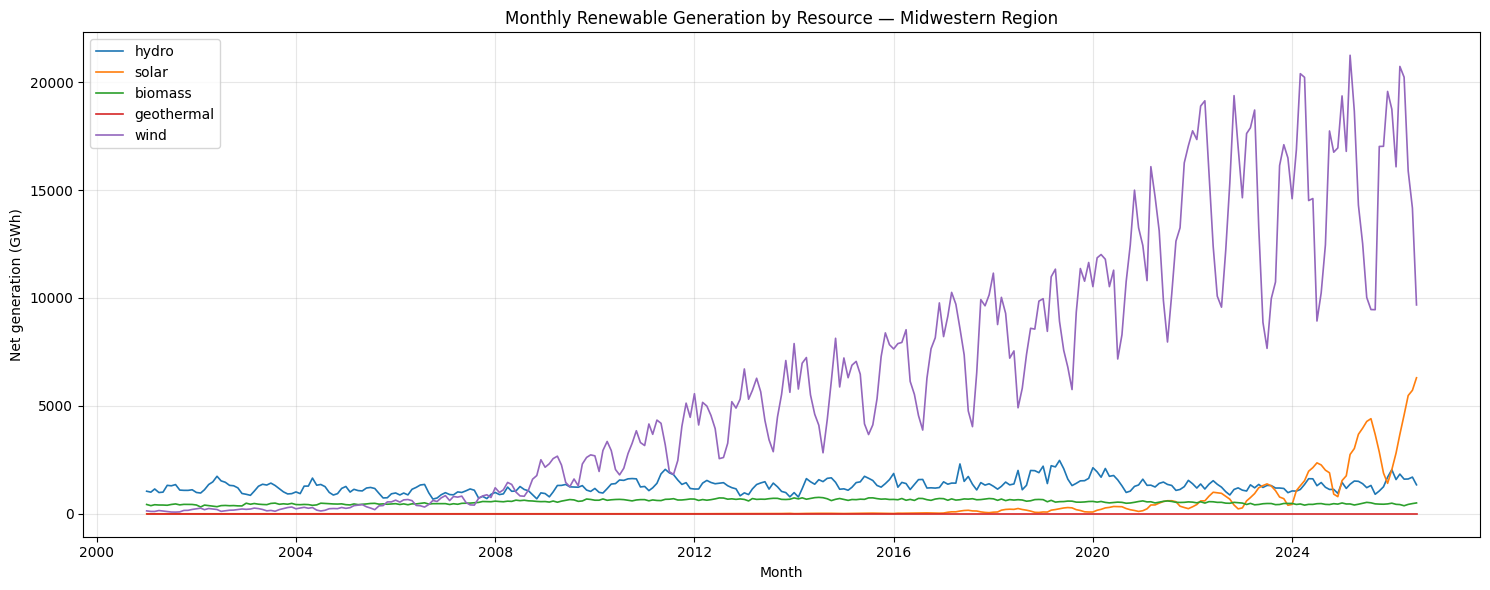

In [10]:
plt.figure(figsize=(15, 6))
for col in ["hydro", "solar", "biomass", "geothermal", "wind"]:
    plt.plot(region.index, region[col], linewidth=1.2, label=col)
plt.xlabel("Month")
plt.ylabel("Net generation (GWh)")
plt.title("Monthly Renewable Generation by Resource — Midwestern Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

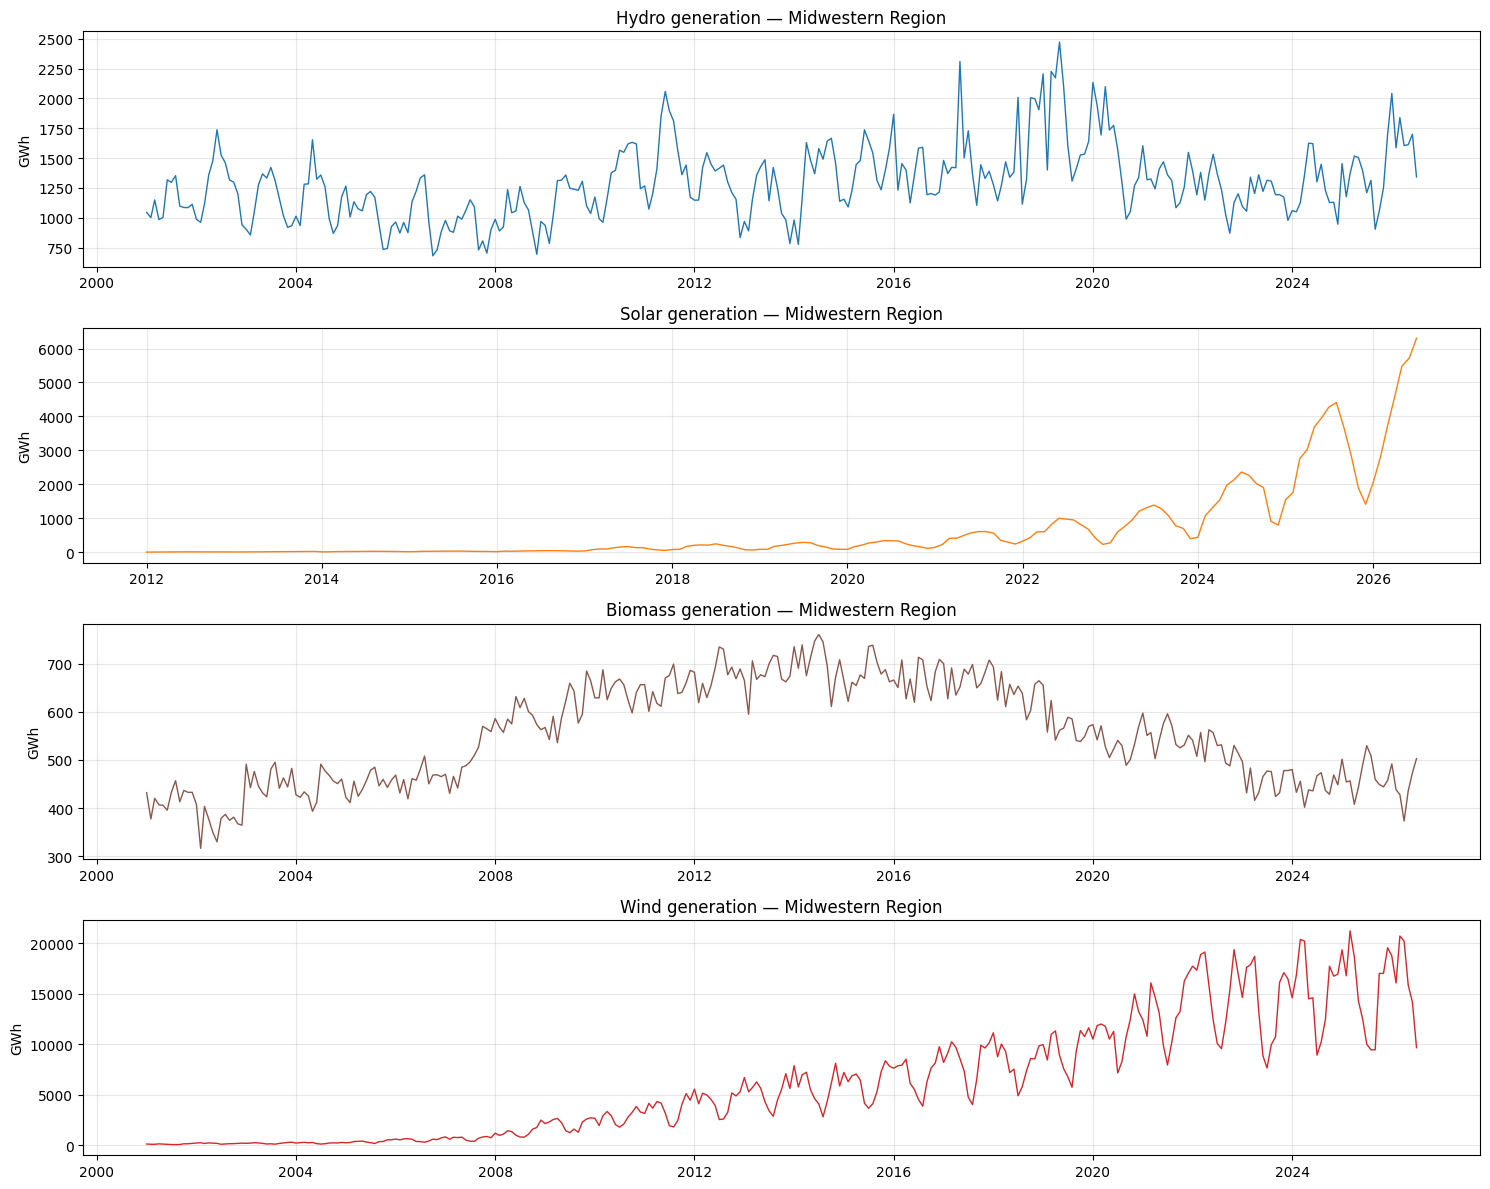

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12))
colors = {"hydro": "tab:blue", "solar": "tab:orange", "biomass": "tab:brown", "wind":"tab:red"}
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].index, series[r].values, color=colors[r], linewidth=1)
    ax.set_title(f"{r.capitalize()} generation — Midwestern Region")
    ax.set_ylabel("GWh")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Initial visual observations**

1. **Hydro** moves between roughly 680 and 2,470 GWh per month. It rose gradually to a high period around 2016–2020, with the record of
   about 2,470 GWh in 2019, and has fallen back since. Each year has a spring/summer high and a winter low. Wet years (2011, 2019) stand out.
2. **Solar** was negligible until about 2017 and has exploded since 2022, reaching about 6,300 GWh in Jul 2026. Its summer peak and winter dip
   repeat every year, and **the swing becomes much larger as the level grows**.
3. **Biomass** follows a clear **hump**. It was about 400–500 GWh in 2001–2007, jumped to a plateau of about 650–750 GWh in 2009–2018, and has declined
   since then to about 450–500 GWh. It has a small seasonal ripple.
4. **Geothermal** is a flat line at zero.

## 5. Trend Analysis

### 12-month rolling mean
A 12-month rolling mean removes the seasonal cycle and leaves the long-term movement.

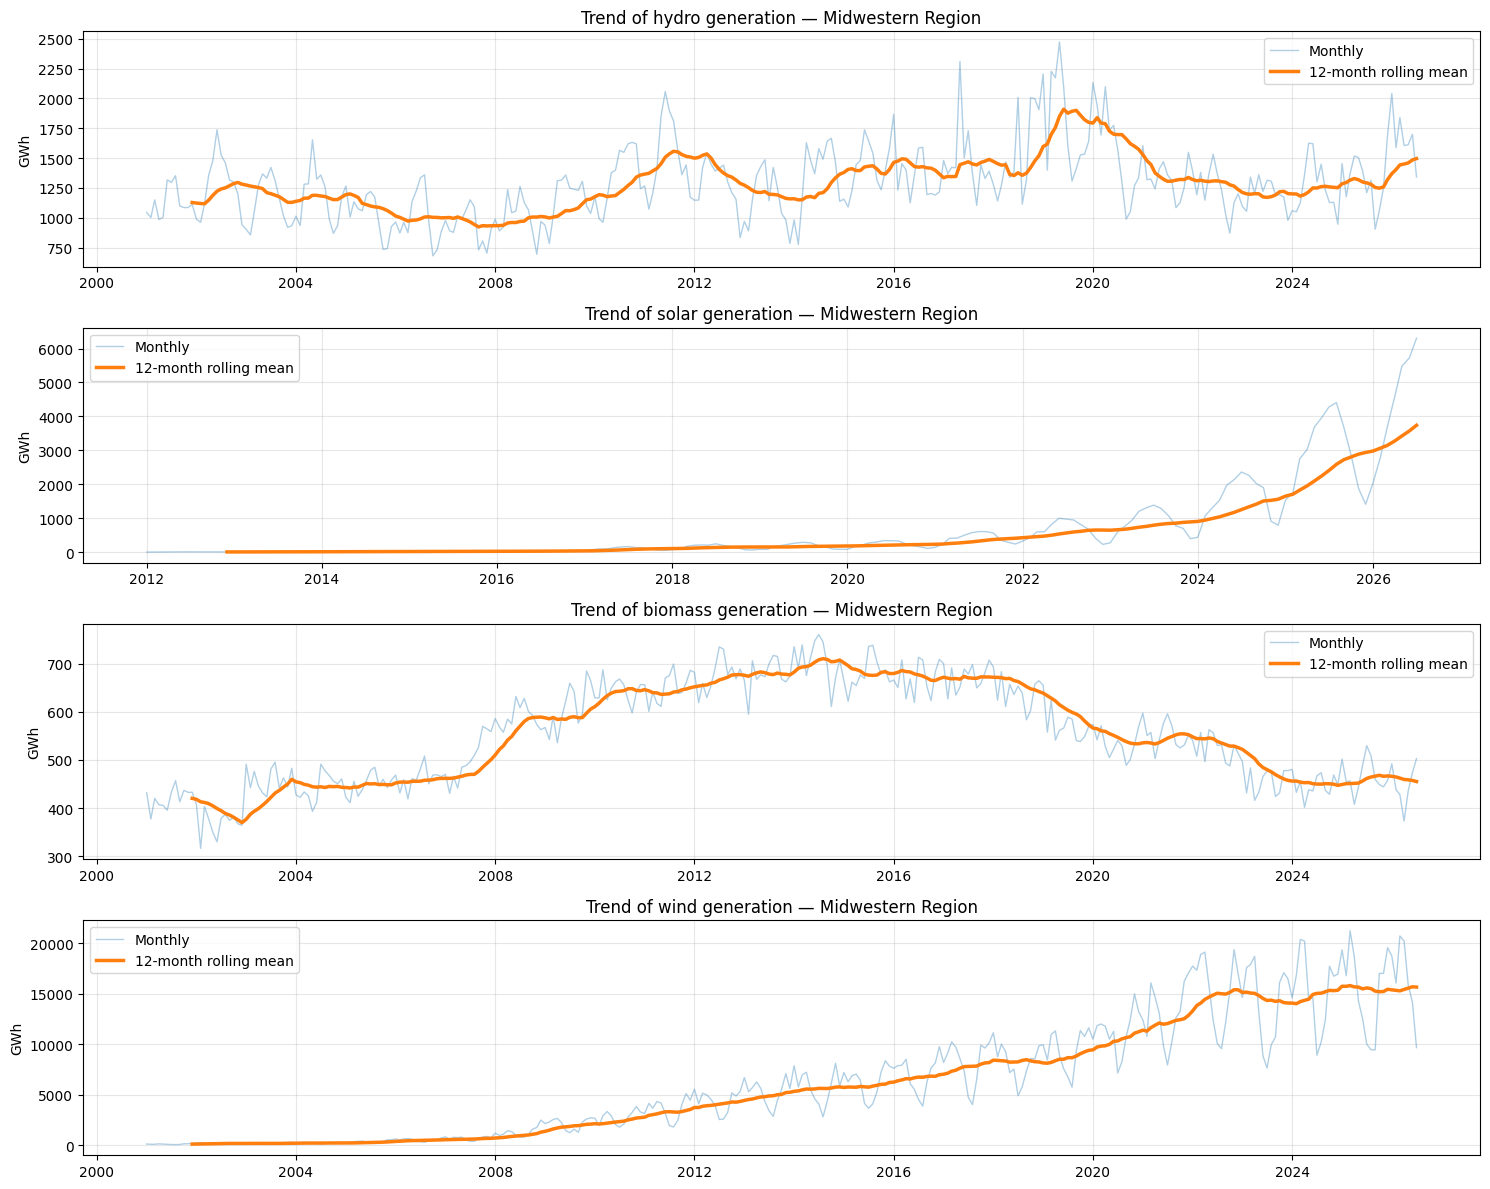

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    ax.plot(s.index, s, alpha=0.35, linewidth=1, label="Monthly")
    ax.plot(s.index, s.rolling(12).mean(), linewidth=2.5, label="12-month rolling mean")
    ax.set_title(f"Trend of {r} generation — Midwestern Region")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Annual totals and growth
Only complete calendar years are used (2026 is partial).

In [13]:
annual = pd.DataFrame({r: series[r].resample("YS").sum() for r in RESOURCES})
annual.index = annual.index.year
annual = annual.loc[:2025]
annual.loc[annual.index < 2012, "solar"] = np.nan

print("Annual generation (GWh):")
print(annual.round(0).to_string())

Annual generation (GWh):
          hydro     solar  biomass       wind
month                                        
2001  13538.000       NaN 5041.000   1502.000
2002  15382.000       NaN 4435.000   2360.000
2003  13551.000       NaN 5517.000   2585.000
2004  14081.000       NaN 5317.000   2818.000
2005  12478.000       NaN 5379.000   4379.000
2006  11995.000       NaN 5540.000   6517.000
2007  11201.000       NaN 6008.000   8360.000
2008  12138.000       NaN 7072.000  15750.000
2009  13885.000       NaN 7271.000  25226.000
2010  16300.000       NaN 7728.000  33031.000
2011  18114.000       NaN 7801.000  42629.000
2012  15463.000    67.000 8131.000  52172.000
2013  13905.000   132.000 8123.000  63045.000
2014  16381.000   220.000 8496.000  69468.000
2015  16855.000   286.000 8157.000  74718.000
2016  16417.000   404.000 8031.000  83942.000
2017  17874.000  1200.000 8072.000  98320.000
2018  18236.000  1815.000 7708.000  99088.000
2019  21597.000  2116.000 6878.000 112887.000
2020  188

### Calculating numerical trend measures
- Removes missing annual observations
- fits a straight line to annual generation versus year.
- slope is the estimated annual change in GWh  
        `CAGR= (V_last/V_first)^(1/n) -1)`
So, slope measures an absolute change in GWh per year
CAGR measures annual growth. Correlation measures how strongly generation is associated with a straight line trend

In [14]:
trend_rows = []
for r in RESOURCES:
    a = annual[r].dropna()
    slope, intercept = np.polyfit(a.index, a.values, 1)          # linear trend in GWh per year
    first, last = a.index.min(), a.index.max()
    cagr = (a.loc[last] / a.loc[first]) ** (1 / (last - first)) - 1
    trend_rows.append({
        "resource": r,
        "years": f"{first}-{last}",
        "first_year_GWh": a.loc[first],
        "last_year_GWh": a.loc[last],
        "linear_slope_GWh_per_year": slope,
        "CAGR_%": cagr * 100,
        "correlation_with_time": np.corrcoef(a.index, a.values)[0, 1],
    })
trend_summary = pd.DataFrame(trend_rows).set_index("resource")
trend_summary

,years,first_year_GWh,last_year_GWh,linear_slope_GWh_per_year,CAGR_%,correlation_with_time
resource,,,,,,
hydro,2001-2025,13538.201,15853.766,172.419,0.660,0.524
solar,2012-2025,67.453,35244.475,1836.990,61.839,0.776
biomass,2001-2025,5041.273,5601.559,42.529,0.440,0.255
wind,2001-2025,1501.618,185410.342,8599.598,22.222,0.970


**Trend interpretation**

| Resource | Long-term behaviour |
|---|---|
| Hydro | **Weak upward drift with large swings.** The slope is +172 GWh/yr (r = 0.52) and the compound growth rate is only 0.66%/yr. Annual output ranges from 11,201 GWh (2007) to 21,597 GWh (2019). It rose until 2019, then fell back to about 15,000–16,000 GWh. |
| Solar | **Explosive, accelerating growth.** Output rose from 67 GWh (2012) to 35,244 GWh (2025), about 62%/yr. 2025 was **1.9 times** 2024 (18,702 GWh). The trend is exponential. |
| Biomass | **Rise then decline.** Output rose from 5,041 GWh (2001) to a peak of 8,496 GWh (2014), then fell back to 5,602 GWh (2025). The linear slope (+43 GWh/yr, r = 0.26) does not describe this hump. |
| Wind | **Rapid, sustained growth.** Output rose from 1,502 GWh (2001) to 185,410 GWh (2025), with a linear slope of +8,600 GWh/yr, a CAGR of 22.22%/yr, and a strong positive correlation with time (r = 0.97). Wind shows the strongest linear association with time among the four resources. |

**Key finding:** The four resources follow different trends: hydro exhibits weak upward drift with large fluctuations, solar shows explosive growth, biomass rises and then declines, and wind experiences rapid, sustained growth.

### Does the variability grow with the level?
If the seasonal swings get larger as the level rises, the seasonality is **multiplicative**, and a log transform (or a multiplicative model) is needed.

In [15]:
for r in RESOURCES:
    s = series[r]
    roll_mean = s.rolling(12).mean()
    roll_std = s.rolling(12).std()
    corr = roll_mean.corr(roll_std)
    print(f"{r:8s}: correlation between 12-month rolling mean and rolling std = {corr:.3f}")

hydro   : correlation between 12-month rolling mean and rolling std = 0.722
solar   : correlation between 12-month rolling mean and rolling std = 0.982
biomass : correlation between 12-month rolling mean and rolling std = 0.148
wind    : correlation between 12-month rolling mean and rolling std = 0.981


**Additive or multiplicative?**

* **Solar:** the rolling mean and rolling std are almost perfectly correlated (0.982), so the seasonality is **multiplicative** and a log transform is needed.
* **Hydro:** the correlation is 0.722, just above the 0.7 threshold. Its swings are larger when the level is higher, so hydro is also treated as **multiplicative** (log scale).
* **Biomass:** the correlation is 0.148, so its variability does not depend on the level. Biomass is treated as **additive**.
* **Wind:** the correlation is 0.981, so its treated as multiplicative(log scale).

## 6. Seasonality Analysis

### Seasonal plot: one line per year

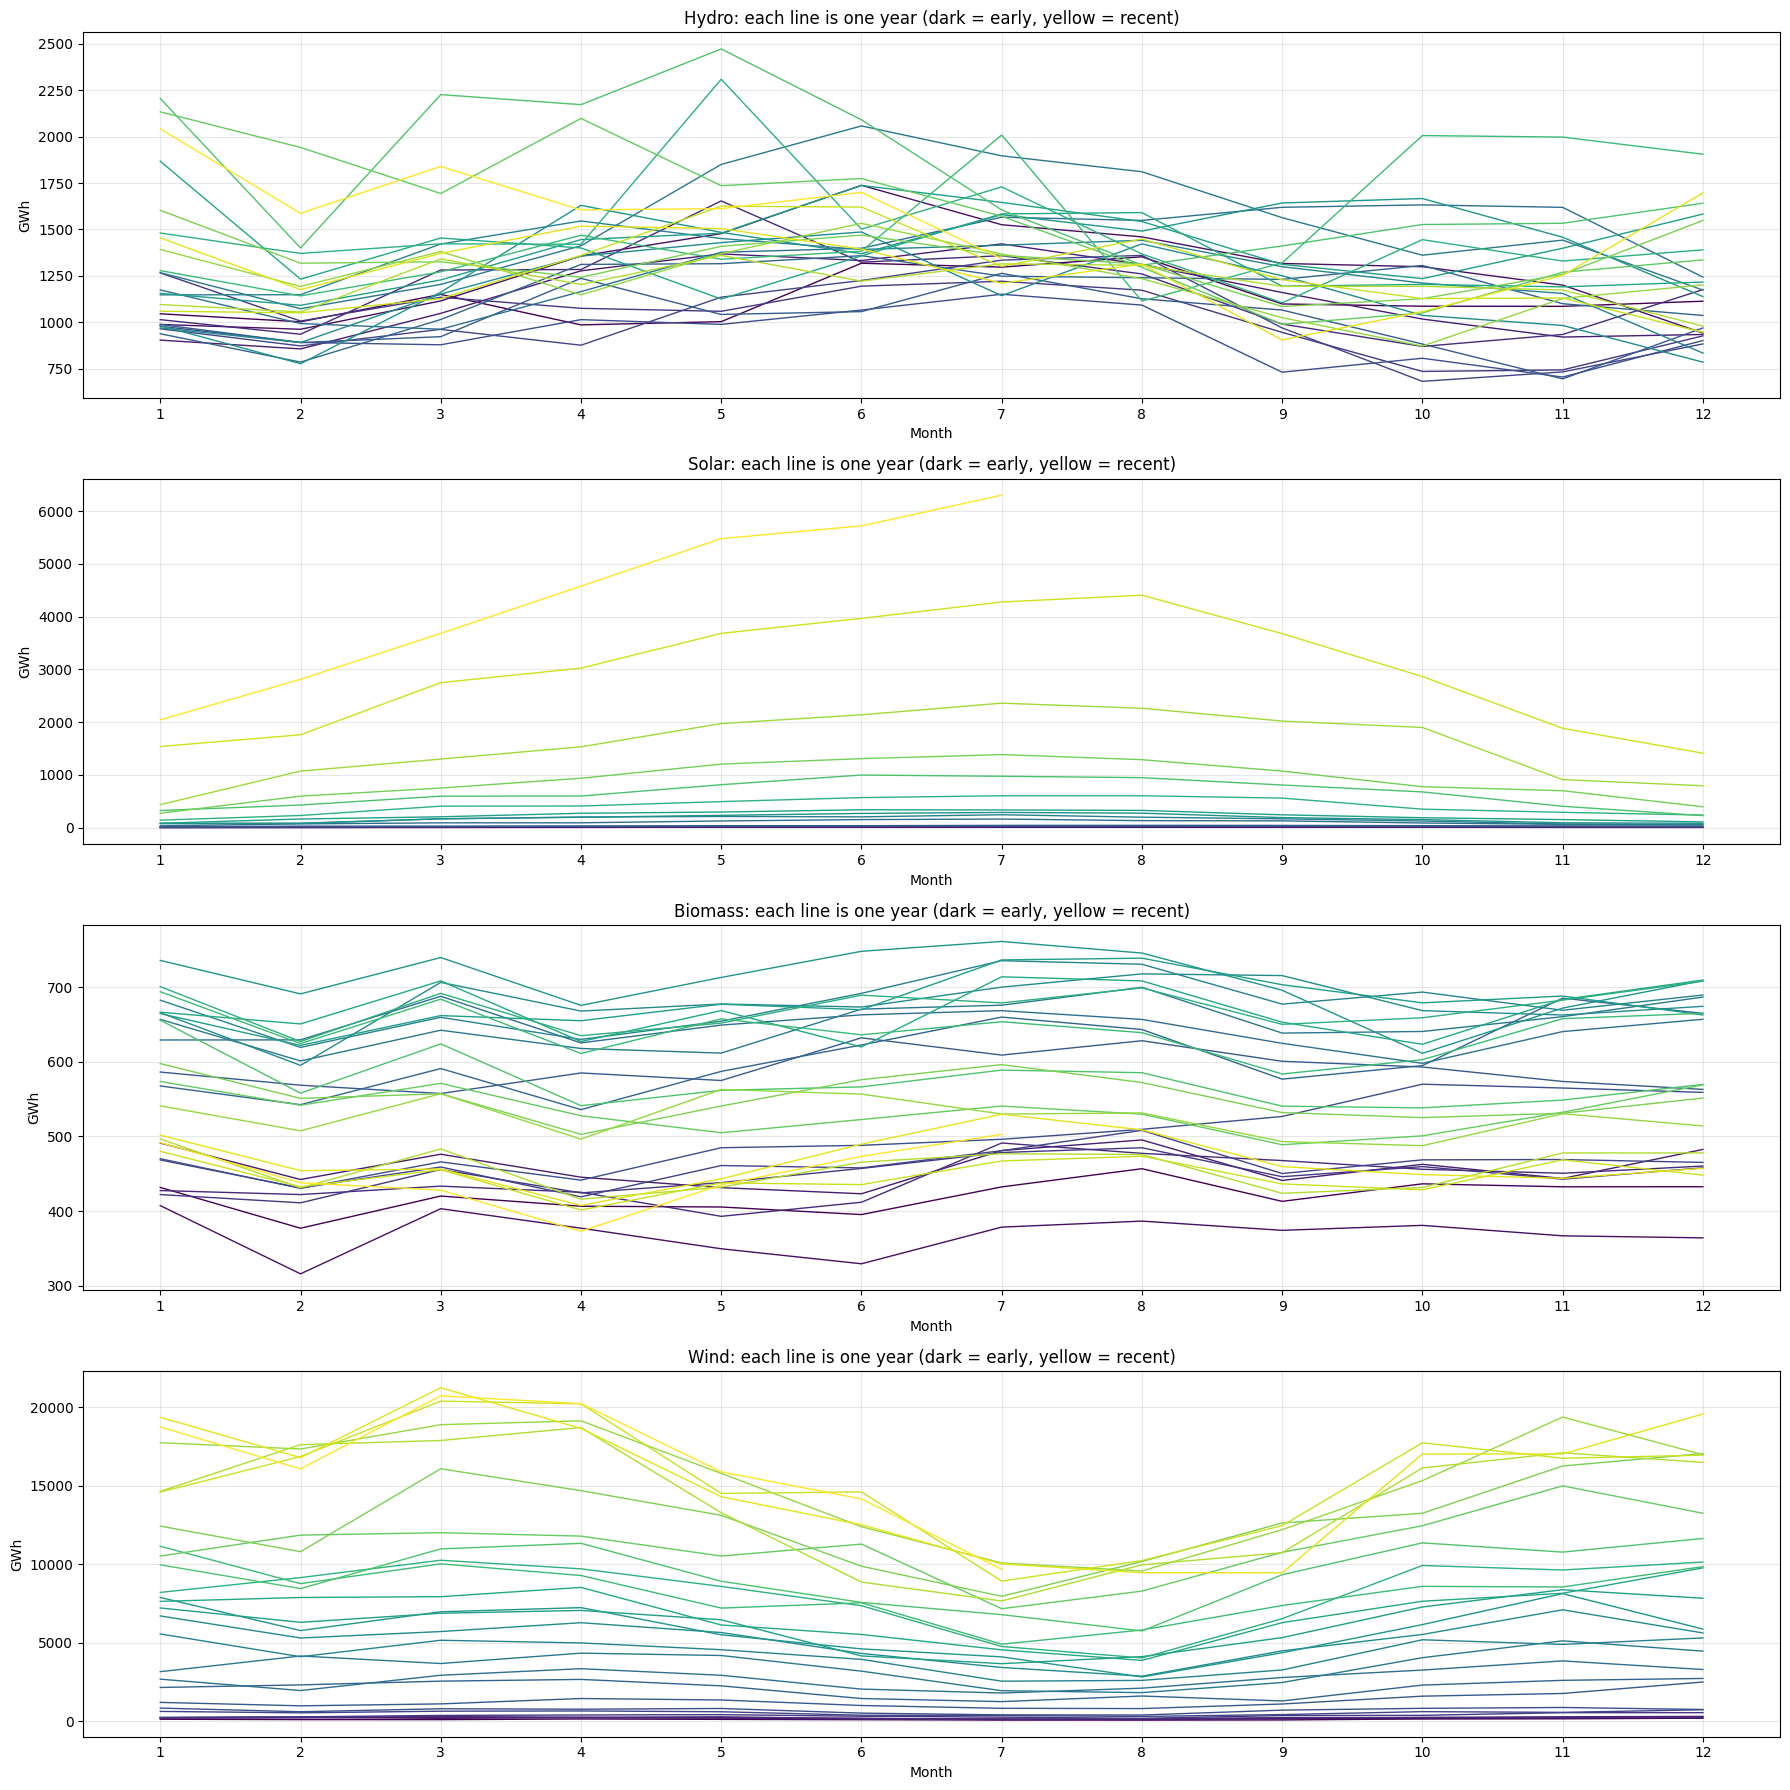

In [18]:
fig, axes = plt.subplots(4, 1, figsize=(18, 18))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    for year in sorted(set(s.index.year)):
        part = s[s.index.year == year]
        ax.plot(part.index.month, part.values, linewidth=1,
                color=plt.cm.viridis((year - s.index.year.min()) / (s.index.year.max() - s.index.year.min())))
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylabel("GWh")
    ax.set_title(f"{r.capitalize()}: each line is one year (dark = early, yellow = recent)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Average monthly profile
To remove the trend first, each month is divided by its own 12-month centred moving average. A value of 1.10 means 10% above the trend level.

       hydro  solar  biomass  wind
month                             
1      0.989  0.525    1.030 1.175
2      0.852  0.750    0.945 1.095
3      0.972  1.017    1.020 1.239
4      1.070  1.104    0.942 1.252
5      1.142  1.276    0.976 1.072
6      1.139  1.388    1.000 0.824
7      1.134  1.428    1.049 0.629
8      1.073  1.346    1.053 0.617
9      0.929  1.144    0.980 0.815
10     0.907  0.900    0.979 1.052
11     0.901  0.682    1.007 1.143
12     0.908  0.535    1.022 1.151


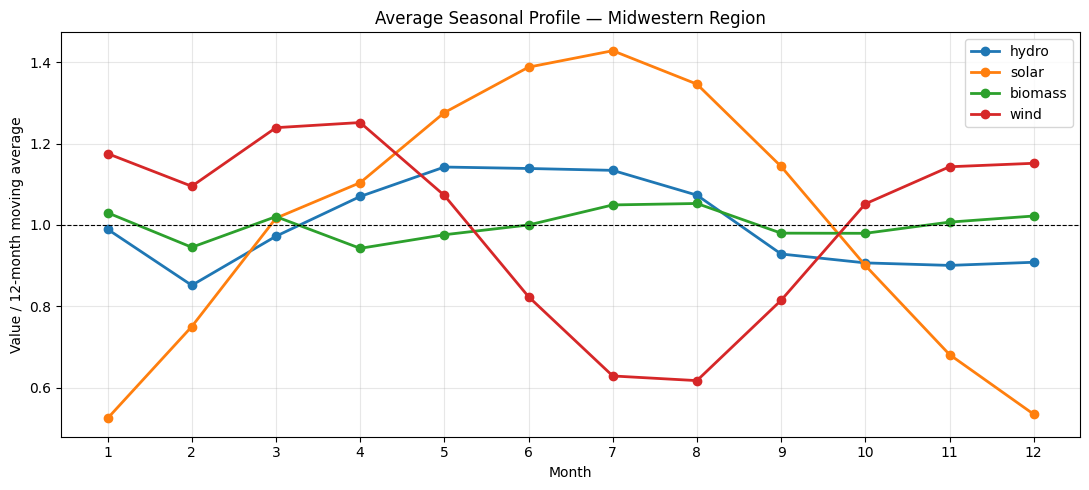

hydro   : peak month =  5 (+14.2%), trough month =  2 (-14.8%)
solar   : peak month =  7 (+42.8%), trough month =  1 (-47.5%)
biomass : peak month =  8 (+5.3%), trough month =  4 (-5.8%)
wind    : peak month =  4 (+25.2%), trough month =  8 (-38.3%)


In [19]:
seasonal_index = {}
for r in RESOURCES:
    s = series[r]
    centred_ma = s.rolling(12, center=True).mean()
    ratio = (s / centred_ma).dropna()
    seasonal_index[r] = ratio.groupby(ratio.index.month).mean()

seasonal_index = pd.DataFrame(seasonal_index)
seasonal_index.index.name = "month"
print(seasonal_index.round(3).to_string())

plt.figure(figsize=(11, 5))
for r in RESOURCES:
    plt.plot(seasonal_index.index, seasonal_index[r], marker="o", linewidth=2, label=r)
plt.axhline(1, color="black", linewidth=0.8, linestyle="--")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Value / 12-month moving average")
plt.title("Average Seasonal Profile — Midwestern Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for r in RESOURCES:
    print(f"{r:8s}: peak month = {seasonal_index[r].idxmax():2d} ({(seasonal_index[r].max()-1)*100:+.1f}%), "
          f"trough month = {seasonal_index[r].idxmin():2d} ({(seasonal_index[r].min()-1)*100:+.1f}%)")

**Seasonal pattern**

| Resource | Peak | Trough | Size | Explanation |
|---|---|---|---|---|
| Hydro | **May** (+14.2% above trend) | **February** (−14.8%) | moderate | April–August are above trend (spring snowmelt and rainfall on the Missouri and upper Mississippi rivers). Late autumn and winter, when rivers are low or frozen, are below trend |
| Solar | **July** (+42.8%) | **January** (−47.5%) | very large | March–September above trend, October–February below. The swing is larger than in the South because of the Midwest's higher latitude (much shorter winter days) |
| Biomass | **August** (+5.3%) | **April** (−5.8%) | small | Slightly higher in mid-summer and mid-winter, lower in spring |
| Wind | **April** (+25.2%) | **August** (−38.3.8%) | Large | Strongest in spring and weakest in summer(opposite to solar's peak) |

**Midwestern hydro and solar peak in roughly the same season** (May and July). The region's
renewable output from these sources is therefore concentrated in spring and summer.

### Month-of-year boxplots

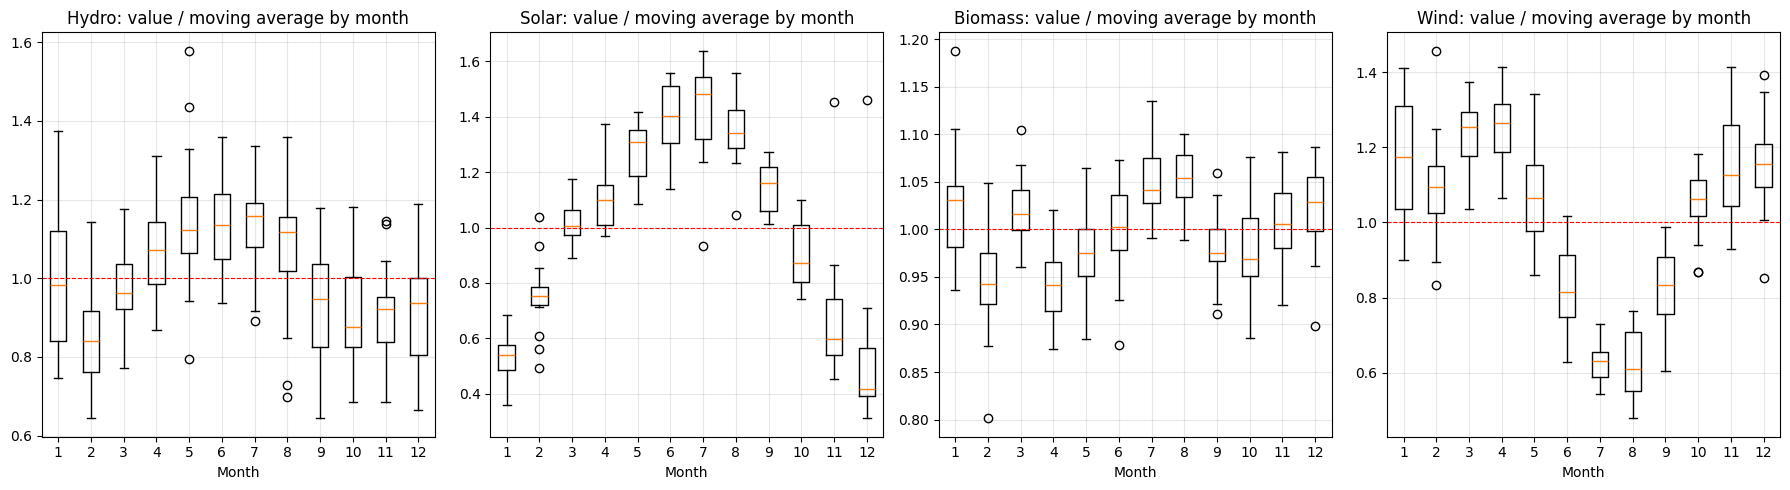

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    ratio = (s / s.rolling(12, center=True).mean()).dropna()
    data = [ratio[ratio.index.month == m].values for m in range(1, 13)]
    ax.boxplot(data, tick_labels=range(1, 13))
    ax.axhline(1, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{r.capitalize()}: value / moving average by month")
    ax.set_xlabel("Month")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal decomposition (period = 12 months)
The decomposition type follows the variance check above: **multiplicative** if the rolling mean and rolling std are strongly correlated (> 0.7), otherwise **additive**.

Decomposition model chosen: {'hydro': 'multiplicative', 'solar': 'multiplicative', 'biomass': 'additive', 'wind': 'multiplicative'}


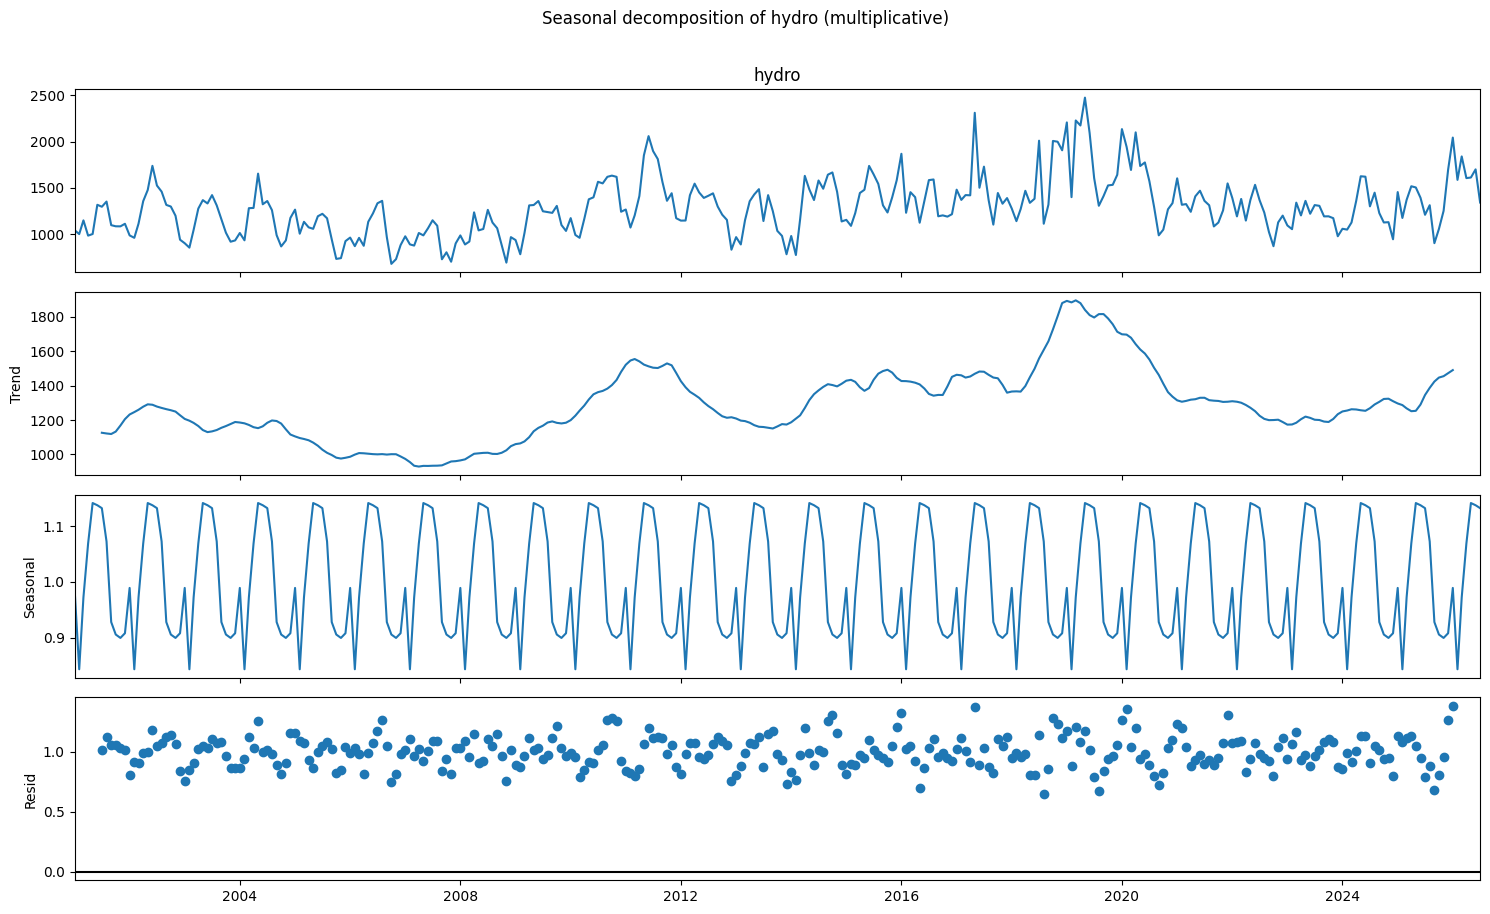

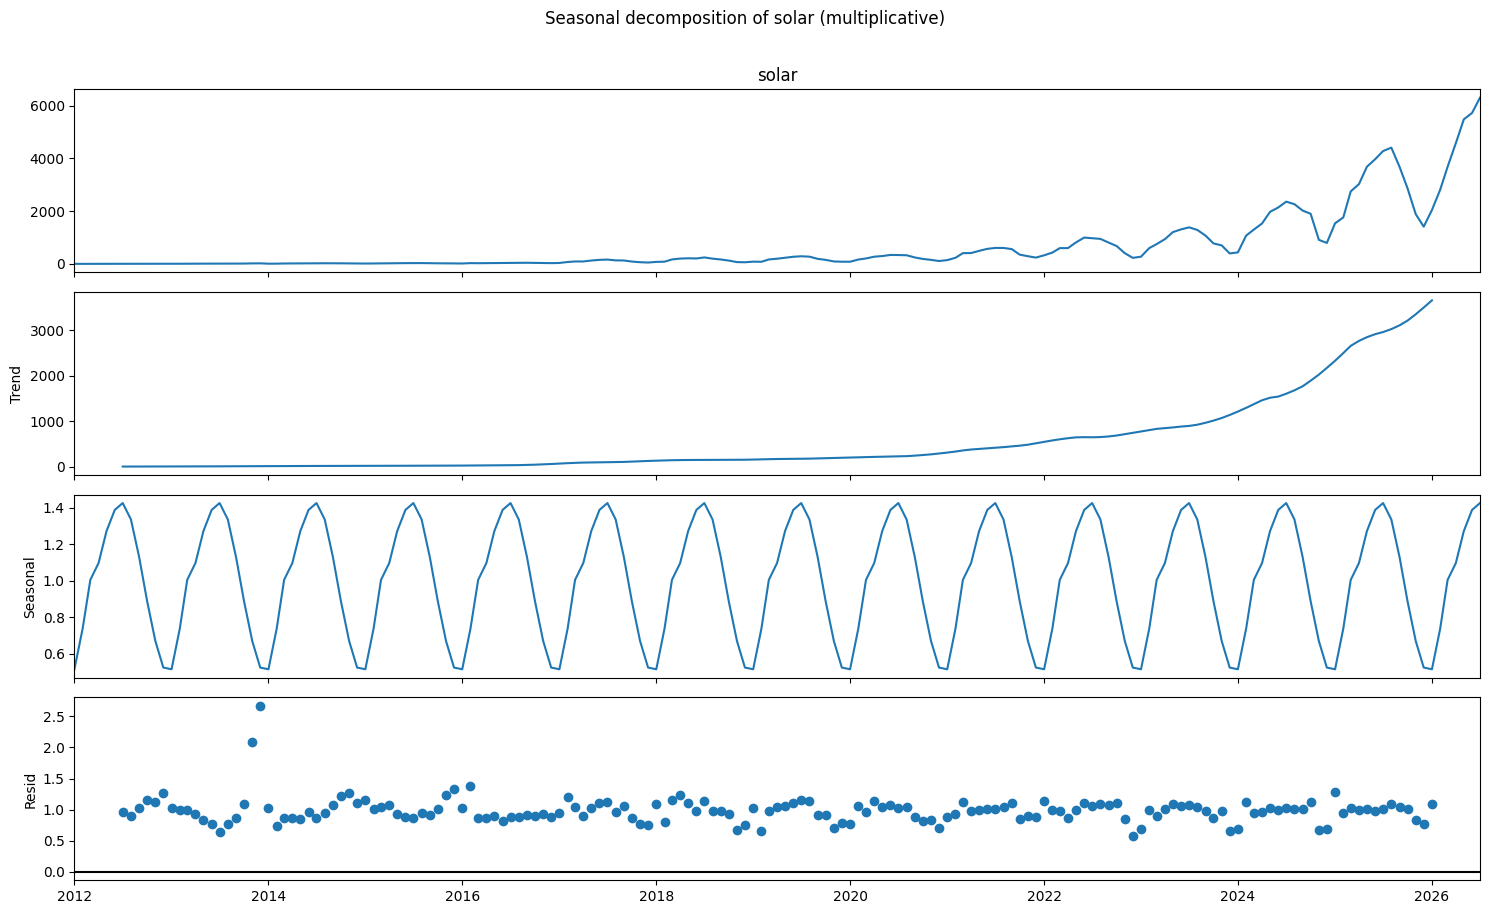

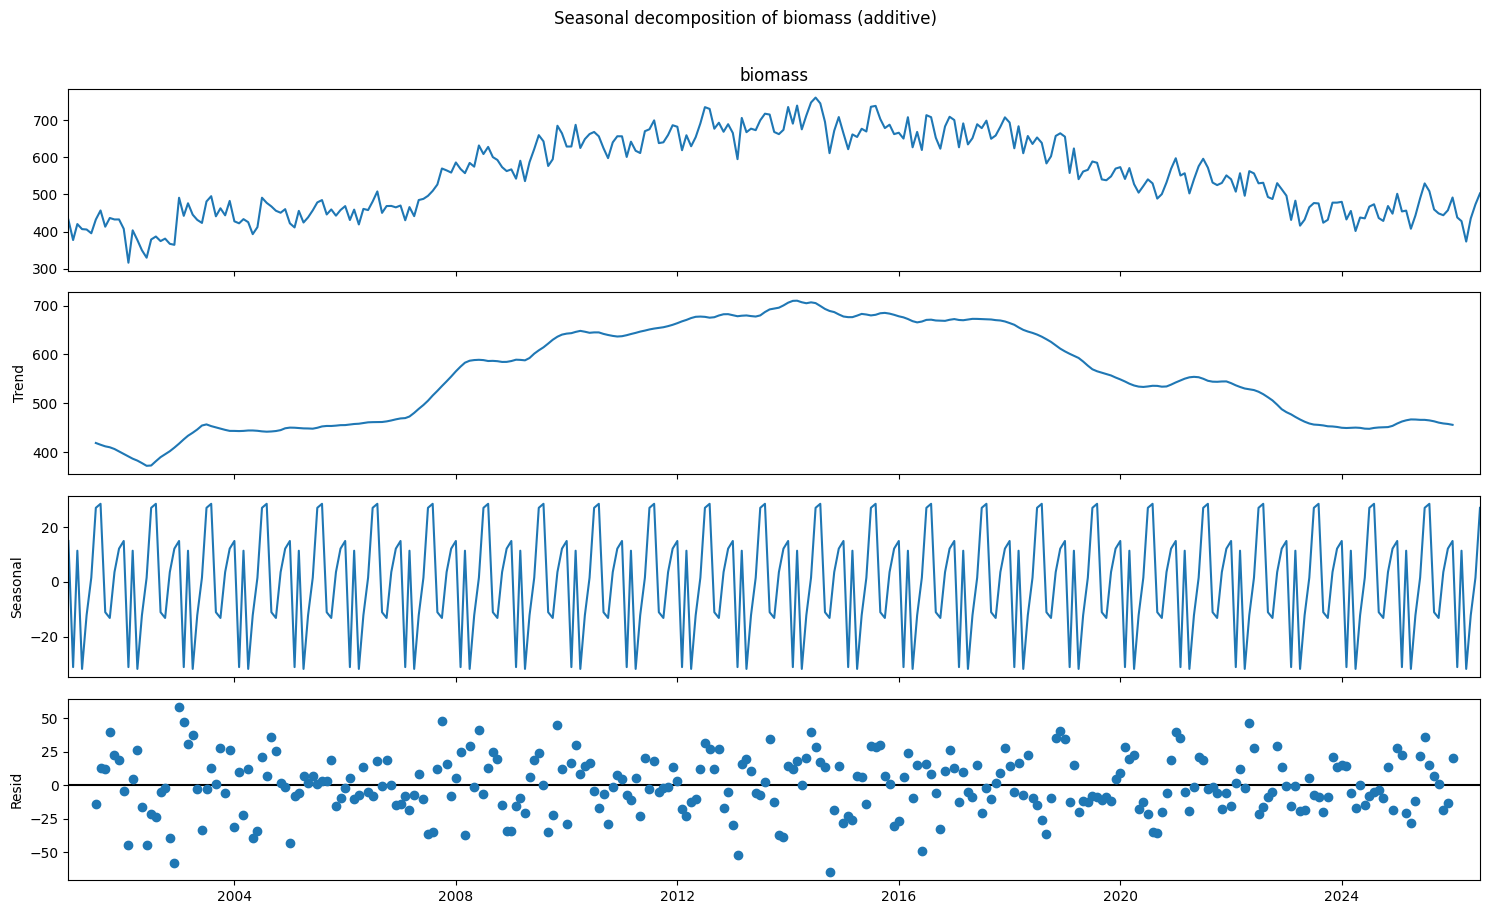

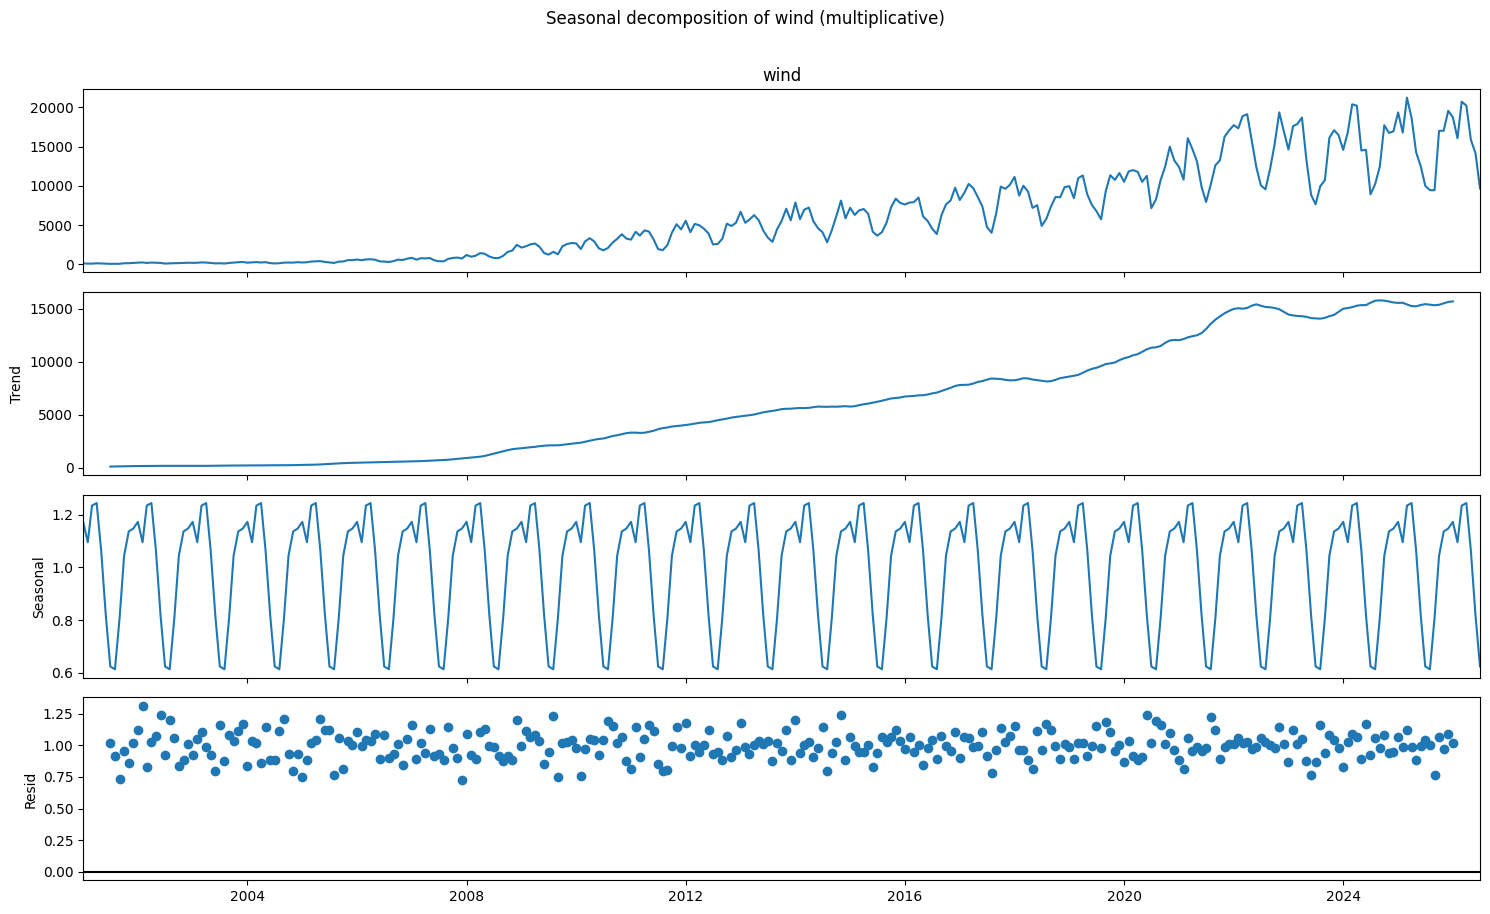

In [21]:
decomp_model = {}
for r in RESOURCES:
    corr = series[r].rolling(12).mean().corr(series[r].rolling(12).std())
    decomp_model[r] = "multiplicative" if corr > 0.7 else "additive"
print("Decomposition model chosen:", decomp_model)
decomposition = {}

for r in RESOURCES:
    decomposition[r] = seasonal_decompose(series[r], model=decomp_model[r], period=12)
    fig = decomposition[r].plot()
    fig.set_size_inches(15, 9)
    fig.suptitle(f"Seasonal decomposition of {r} ({decomp_model[r]})", y=1.01)
    plt.tight_layout()
    plt.show()

In [22]:
# Seasonal strength (0 = no seasonality, 1 = only seasonality) = 1 - Var(residual) / Var(seasonal + residual)
strength_rows = []
for r in RESOURCES:
    d = decomposition[r]
    if decomp_model[r] == "multiplicative":       # work on the log scale so the parts add up
        seas, resid, trend = np.log(d.seasonal), np.log(d.resid), np.log(d.trend)
    else:
        seas, resid, trend = d.seasonal, d.resid, d.trend
    seas, resid, trend = seas[resid.notna()], resid.dropna(), trend.dropna()
    strength_rows.append({
        "resource": r,
        "seasonal_strength": max(0, 1 - resid.var() / (seas + resid).var()),
        "trend_strength": max(0, 1 - resid.var() / (trend + resid).var()),
    })
strength = pd.DataFrame(strength_rows).set_index("resource")
strength

,seasonal_strength,trend_strength
resource,,
hydro,0.367,0.587
solar,0.802,0.989
biomass,0.457,0.957
wind,0.829,0.995


**Seasonal decomposition interpretation**

* **Hydro** (multiplicative): seasonal strength 0.37 and trend strength 0.59. The seasonal cycle is real but the **irregular component is large**, driven by wet and dry years.
* **Solar** (multiplicative): trend strength 0.99 and seasonal strength 0.80. Solar is almost entirely trend plus a very regular summer cycle.
* **Biomass** (additive): trend strength 0.96 and seasonal strength 0.46. The slow rise-and-decline trend dominates, with only a modest seasonal component.
* **Wind** (multiplicative): Trend strength is 1.00 (0.995) and seasonal strength is 0.83. Wind generation is strongly dominated by its long-term trend, with a pronounced seasonal pattern. The relatively high seasonal strength indicates that seasonality explains a substantial part of the variation remaining after accounting for the trend.

### ACF of the original series
For monthly data, repeated peaks at lags 12, 24, 36 indicate a **yearly seasonal cycle**.

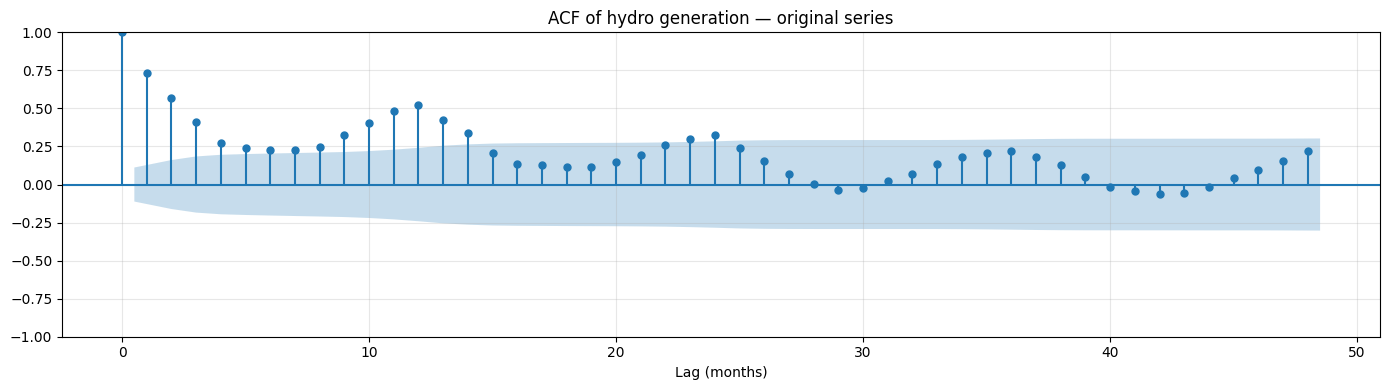

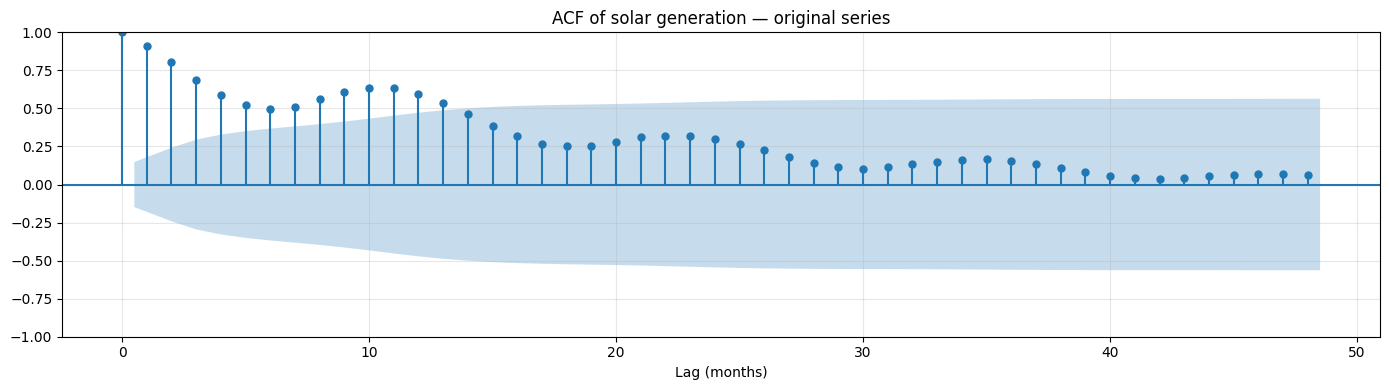

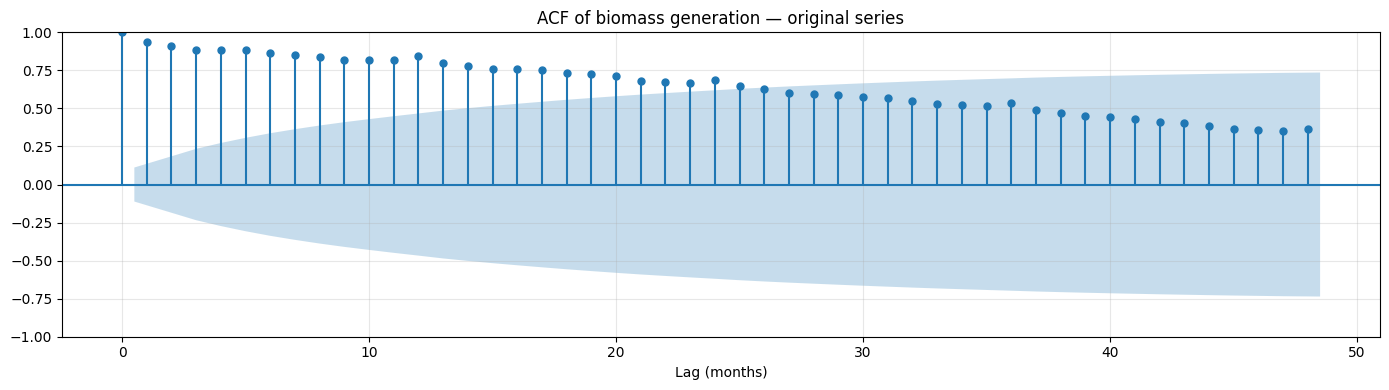

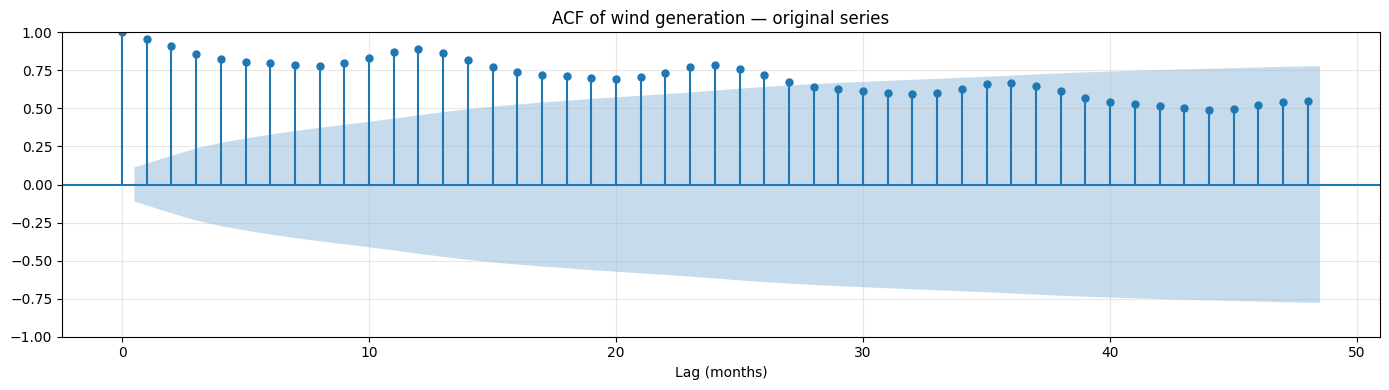

In [23]:
for r in RESOURCES:
    plt.figure(figsize=(14, 4))
    plot_acf(series[r], lags=48, ax=plt.gca())
    plt.title(f"ACF of {r} generation — original series")
    plt.xlabel("Lag (months)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

**ACF interpretation (original series)**

- **Hydro:** The ACF decays from 0.73 (lag 1) to about 0.24 (lag 5), then **rises again to 0.52 at lag 12** and 0.33 at lag 24. This shows short-term persistence plus a clear yearly cycle.
- **Solar:** The ACF decays slowly (0.91 at lag 1, about 0.5 by lag 6) with a **bump at lag 12 (0.60)**. This shows trend plus seasonality.
- **Biomass:** The ACF stays **very high for a long time**: 0.93 at lag 1, 0.84 at lag 12 and still 0.54 at lag 36. Such slow decay is the classic signature of a **non-stationary**, trend-dominated series.
- **Wind:** The ACF starts at 1.00 at lag 0 and remains **strongly positive throughout the 48-month range**, declining gradually from about 0.95 at lag 1 to around 0.55 at lag 48. It also shows a mild rise around lags 10–13 and 22–25, suggesting a possible yearly pattern. The slow decay indicates strong persistence and a substantial long-term trend. The repeating bumps are consistent with annual seasonality, though the trend may contribute to the high autocorrelation across many lags.

## 7. Stationarity Analysis

1. **ADF test**: H0 = the series has a unit root (non-stationary). p < 0.05 means stationary.
2. **KPSS test**: H0 = the series is stationary. p < 0.05 means non-stationary.

A series is called stationary only when **both** tests agree. The KPSS p-value is limited by its lookup table to the range 0.01–0.10.

In [24]:
alpha = 0.05

def stationarity_tests(x, name):
    x = x.dropna()
    adf_result = adfuller(x, regression="ct" if name.endswith("(original)") else "c")
    kpss_result = kpss(x, regression="ct" if name.endswith("(original)") else "c", nlags="auto")
    adf_ok = adf_result[1] < alpha
    kpss_ok = kpss_result[1] > alpha
    if adf_ok and kpss_ok:
        verdict = "Stationary"
    elif not adf_ok and not kpss_ok:
        verdict = "Non-stationary"
    else:
        verdict = "Mixed evidence"
    return {"series": name, "n": len(x), "ADF statistic": adf_result[0], "ADF p-value": adf_result[1],
            "KPSS statistic": kpss_result[0], "KPSS p-value": kpss_result[1], "Conclusion": verdict}

### 7.1 Original series (with constant + trend)

In [25]:
original_tests = pd.DataFrame([stationarity_tests(series[r], f"{r} (original)") for r in RESOURCES])
original_tests

,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,hydro (original),307,-2.681,0.244,0.184,0.022,Non-stationary
1,solar (original),175,-2.169,0.507,0.399,0.010,Non-stationary
2,biomass (original),307,-0.818,0.964,0.695,0.010,Non-stationary
3,wind (original),307,-2.545,0.306,0.566,0.010,Non-stationary


In [26]:
# Detailed output for one series, in the same format as the ADF / KPSS printouts
for r in RESOURCES:
    adf_result = adfuller(series[r].dropna(), regression="ct")
    print(f"ADF TEST - {r.upper()} (ORIGINAL SERIES)")
    print("-" * 50)
    print(f"ADF Statistic : {adf_result[0]:.6f}")
    print(f"p-value       : {adf_result[1]:.10f}")
    print(f"Lags Used     : {adf_result[2]}")
    print(f"Observations  : {adf_result[3]}")
    print("Critical Values:", {k: round(v, 3) for k, v in adf_result[4].items()})
    print()

ADF TEST - HYDRO (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -2.681059
p-value       : 0.2440307580
Lags Used     : 14
Observations  : 292
Critical Values: {'1%': -3.99, '5%': -3.426, '10%': -3.136}

ADF TEST - SOLAR (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -2.169457
p-value       : 0.5070514210
Lags Used     : 14
Observations  : 160
Critical Values: {'1%': -4.016, '5%': -3.438, '10%': -3.143}

ADF TEST - BIOMASS (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -0.817839
p-value       : 0.9641465030
Lags Used     : 12
Observations  : 294
Critical Values: {'1%': -3.99, '5%': -3.426, '10%': -3.136}

ADF TEST - WIND (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -2.544629
p-value       : 0.3060202068
Lags Used     : 15
Observations  : 291
Critical Values: {'1%': -3.99, '5%': -3.426, '10%': -3.136}



**Stationarity of the original series**

| Resource | ADF p-value | KPSS p-value | Conclusion |
|---|---:|---:|---|
| Hydro | 0.244 | 0.022 | **Non-stationary** |
| Solar | 0.507 | 0.010 | **Non-stationary** |
| Biomass | 0.964 | 0.010 | **Non-stationary** |
| Wind | 0.306 | 0.010 | **Non-stationary** |

All four original series are non-stationary, as supported by both the ADF and KPSS tests. For every resource, the ADF p-value is greater than 0.05, so the null hypothesis of a unit root cannot be rejected. The KPSS p-value is at or below 0.05, so the null hypothesis of stationarity is rejected.

Therefore, **differencing or another suitable transformation should be considered for all four resources** before time-series modelling.

### 7.2 Making the series stationary
We test the decomposition residual (trend and seasonality removed), the first difference (Δ), the seasonal difference (Δ12) and both together. Resources with multiplicative seasonality are log-transformed first.

In [27]:
# log makes growing seasonal swings constant (only for multiplicative resources)
transformed = {r: np.log(series[r]) if decomp_model[r] == "multiplicative" else series[r] for r in RESOURCES}
print("Log-transformed:", [r for r in RESOURCES if decomp_model[r] == "multiplicative"])

rows = []
for r in RESOURCES:
    z = transformed[r]
    resid = decomposition[r].resid
    if decomp_model[r] == "multiplicative":
        resid = np.log(resid)
    rows.append(stationarity_tests(z, f"{r}: level, constant only (no trend term)"))
    rows.append(stationarity_tests(resid, f"{r}: decomposition residual"))
    rows.append(stationarity_tests(z.diff(), f"{r}: first difference (d=1)"))
    rows.append(stationarity_tests(z.diff(12), f"{r}: seasonal difference (D=1)"))
    rows.append(stationarity_tests(z.diff(12).diff(), f"{r}: both (d=1, D=1)"))
transformed_tests = pd.DataFrame(rows)
transformed_tests

Log-transformed: ['hydro', 'solar', 'wind']


,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,"hydro: level, constant only (no trend term)",307,-1.809,0.376,1.207,0.010,Non-stationary
1,hydro: decomposition residual,295,-7.881,0.000,0.007,0.100,Stationary
2,hydro: first difference (d=1),306,-7.819,0.000,0.027,0.100,Stationary
3,hydro: seasonal difference (D=1),295,-3.902,0.002,0.060,0.100,Stationary
4,"hydro: both (d=1, D=1)",294,-7.152,0.000,0.026,0.100,Stationary
5,"solar: level, constant only (no trend term)",175,-0.207,0.938,1.844,0.010,Non-stationary
6,solar: decomposition residual,163,-3.672,0.005,0.142,0.100,Stationary
7,solar: first difference (d=1),174,-4.091,0.001,0.033,0.100,Stationary
8,solar: seasonal difference (D=1),163,-4.225,0.001,0.101,0.100,Stationary
9,"solar: both (d=1, D=1)",162,-3.856,0.002,0.065,0.100,Stationary


**Stationarity analysis: final interpretation**

- **Hydro (log scale):** The level is non-stationary (ADF p = 0.376, KPSS p = 0.010). A **first difference** makes it stationary (ADF p < 0.001, KPSS p ≥ 0.10). The seasonal difference is also stationary, but hydro's seasonal strength is only 0.37, so a seasonal difference is not needed; seasonality can instead be modelled with seasonal AR/MA terms. Use **d = 1, D = 0**.

- **Solar (log scale):** A **seasonal difference alone** makes it stationary (ADF p = 0.001, KPSS p ≥ 0.10). Use **d = 0, D = 1**. Applying both differences may cause over-differencing.

- **Biomass:** The level is non-stationary; the seasonal difference alone remains non-stationary (ADF p = 0.123). The **first difference** is stationary (ADF p < 0.001, KPSS p ≥ 0.10), while applying both differences gives mixed evidence (KPSS p = 0.042), potentially indicating over-differencing. Use **d = 1, D = 0**.

- **Wind (log scale):** The level is non-stationary (ADF p = 0.261, KPSS p = 0.010). A **first difference** makes it stationary (ADF p = 0.003, KPSS p ≥ 0.10). The seasonal difference alone remains non-stationary (ADF p = 0.194, KPSS p = 0.010), while applying both differences produces stationarity (ADF p < 0.001, KPSS p ≥ 0.10). Since first differencing alone is sufficient, start with **d = 1, D = 0** and assess whether seasonal AR/MA terms adequately capture the remaining seasonality.

The decomposition residuals of all four resources are stationary according to both tests. This suggests that the decomposition has removed the trend and seasonal structure sufficiently for the residuals to be stationary.

## 8. ACF / PACF Analysis of the Stationary Series
The ACF and PACF are examined on the differenced series selected above. This is the series an ARIMA/SARIMA model works with.

hydro   : d=1, D=0 -> Δ log(hydro)
solar   : d=0, D=1 -> Δ12 log(solar)
biomass : d=1, D=0 -> Δ biomass
wind    : d=1, D=1 -> Δ Δ12 log(wind)


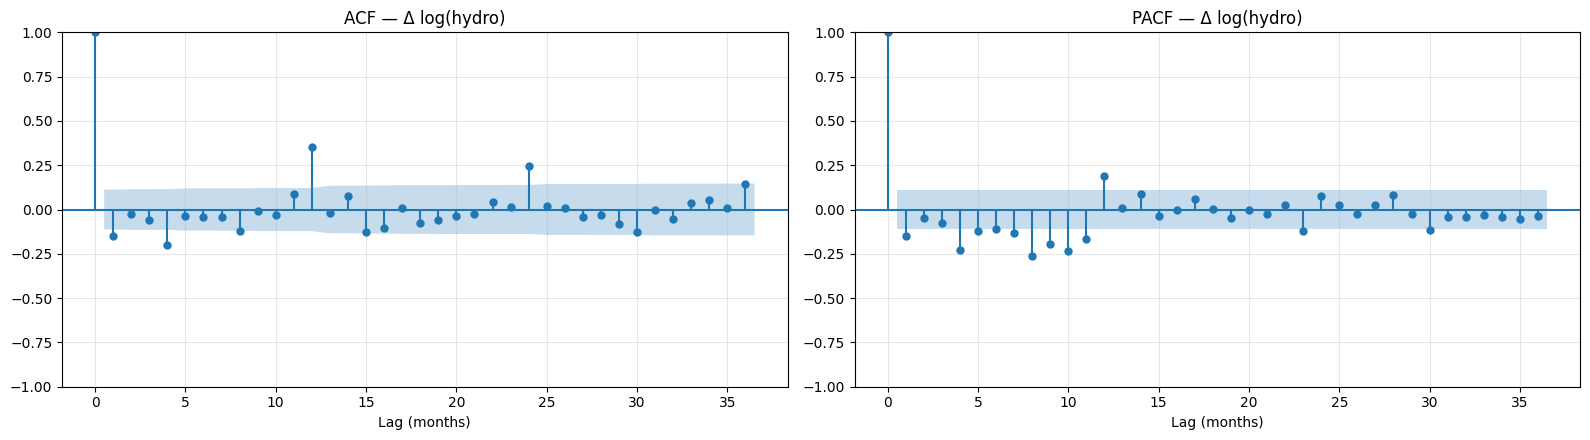

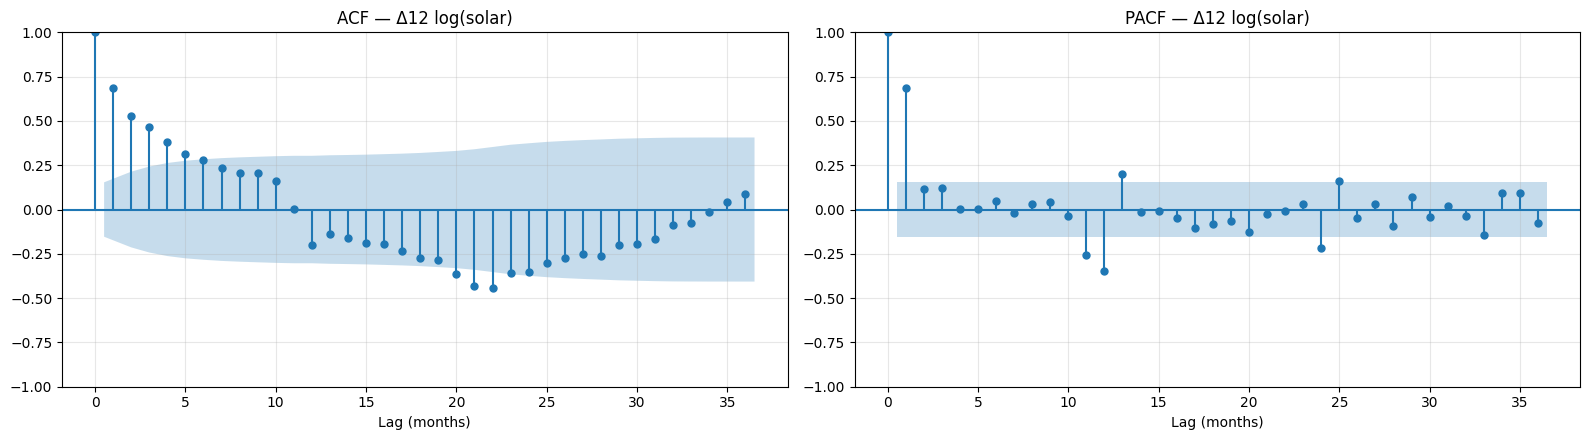

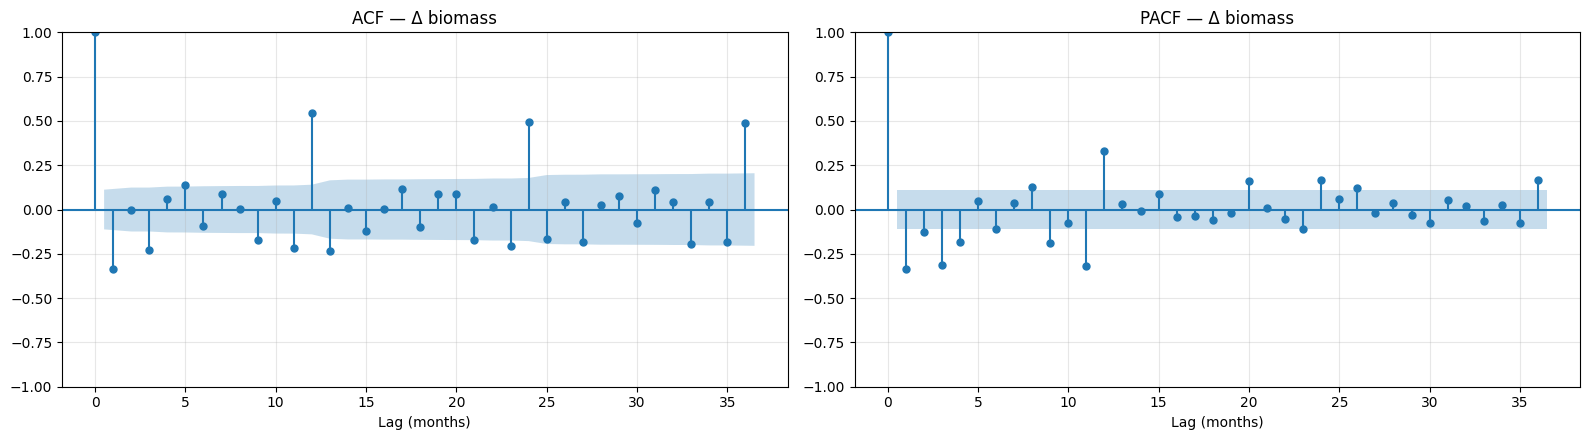

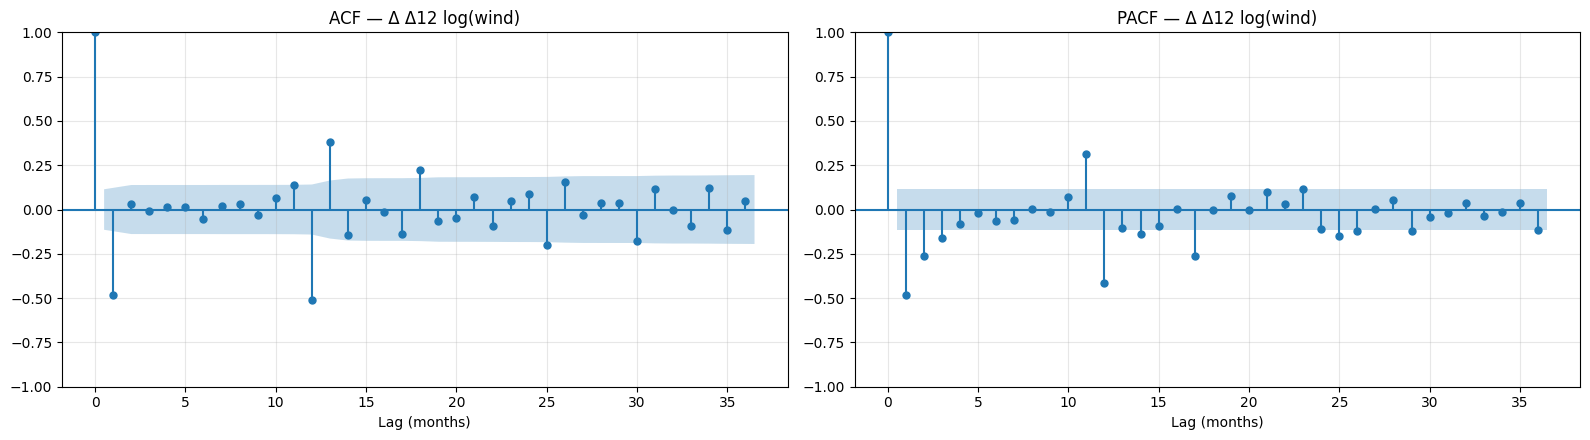

In [28]:
# Differencing rule (the same rule is applied automatically in Review 2):
#   D = 1 if the seasonal strength > 0.64 (strong seasonality -> seasonal difference)
#   d = 1 if the series (after D) is still not stationary by BOTH ADF (p<0.05) and KPSS (p>0.05)
def choose_differencing(z):
    parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = parts.resid.dropna(), parts.seasonal[parts.resid.notna()]
    D = 1 if max(0, 1 - resid.var() / (seas + resid).var()) > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    d = 0 if (adfuller(x)[1] < 0.05 and kpss(x, regression="c", nlags="auto")[1] > 0.05) else 1
    return d, D

stationary, stationary_label = {}, {}
for r in RESOURCES:
    d, D = choose_differencing(transformed[r])
    x = transformed[r]
    if D: x = x.diff(12)
    if d: x = x.diff()
    stationary[r] = x.dropna()
    name = f"log({r})" if decomp_model[r] == "multiplicative" else r
    stationary_label[r] = ("Δ " if d else "") + ("Δ12 " if D else "") + name + ("" if d or D else " (level)")
    print(f"{r:8s}: d={d}, D={D} -> {stationary_label[r]}")

for r in RESOURCES:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    plot_acf(stationary[r], lags=36, ax=axes[0])
    plot_pacf(stationary[r], lags=36, method="ywm", ax=axes[1])
    axes[0].set_title(f"ACF — {stationary_label[r]}")
    axes[1].set_title(f"PACF — {stationary_label[r]}")
    for ax in axes:
        ax.set_xlabel("Lag (months)")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [29]:
from statsmodels.tsa.stattools import acf, pacf

acf_rows = []
for r in RESOURCES:
    x = stationary[r]
    bound = 1.96 / np.sqrt(len(x))
    a = acf(x, nlags=36)
    p = pacf(x, nlags=36, method="ywm")
    acf_rows.append({
        "resource": r,
        "series": stationary_label[r],
        "ACF lag 1": a[1], "ACF lag 12": a[12], "PACF lag 1": p[1], "PACF lag 12": p[12],
        "significant ACF lags (≤13)": [k for k in range(1, 14) if abs(a[k]) > bound],
        "significant PACF lags (≤13)": [k for k in range(1, 14) if abs(p[k]) > bound],
        "95% bound": bound,
    })
acf_summary = pd.DataFrame(acf_rows).set_index("resource")
acf_summary

,series,ACF lag 1,ACF lag 12,PACF lag 1,PACF lag 12,significant ACF lags (≤13),significant PACF lags (≤13),95% bound
resource,,,,,,,,
hydro,Δ log(hydro),-0.147,0.351,-0.147,0.188,"[1, 4, 8, 12]","[1, 4, 5, 7, 8, 9, 10, 11, 12]",0.112
solar,Δ12 log(solar),0.684,-0.199,0.684,-0.345,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]","[1, 11, 12, 13]",0.154
biomass,Δ biomass,-0.335,0.547,-0.335,0.333,"[1, 3, 5, 9, 11, 12, 13]","[1, 2, 3, 4, 8, 9, 11, 12]",0.112
wind,Δ Δ12 log(wind),-0.482,-0.513,-0.482,-0.414,"[1, 11, 12, 13]","[1, 2, 3, 11, 12]",0.114


**ACF / PACF interpretation and suggested models**

| Resource | Pattern on the stationary series | Suggested model |
|---|---|---|
| Hydro (Δ log) | Small negative ACF at lag 1 (−0.15), which is commonly associated with first differencing and suggests an **MA(1)** term. A positive spike at lag 12 (ACF 0.35, PACF 0.19) indicates that yearly dependence remains, suggesting seasonal AR and/or MA terms. | SARIMA(1,1,1)(1,0,1)₁₂ |
| Solar (Δ12 log) | ACF starts at 0.68 and decays gradually over lags 1–10, while the PACF has its strongest spike at lag 1, suggesting an **AR(1)** component. The PACF spike at lag 12 (−0.35) also suggests seasonal dependence. | SARIMA(1,0,0)(1,1,1)₁₂ with drift |
| Biomass (Δ) | ACF at lag 1 (−0.34) suggests an **MA(1)** component. Strong positive seasonal spikes at lag 12 (ACF 0.55, PACF 0.33) suggest seasonal AR and/or MA terms. | SARIMA(1,1,1)(1,0,1)₁₂ |
| Wind (Δ Δ12 log) | Strong negative ACF spikes at lag 1 (−0.48) and lag 12 (−0.51), with negative PACF values at both lags (−0.48 and −0.41). This indicates substantial short-term and annual dependence remains after both differences. The pattern suggests investigating **non-seasonal MA and seasonal MA terms**, while checking whether applying both differences has over-differenced the series. | Start by comparing SARIMA(1,1,1)(0,1,1)₁₂ and simpler alternatives using AIC and residual diagnostics. |

The ACF/PACF plots provide candidate model orders rather than definitive specifications. The final models should be selected using information criteria such as AIC and validated with residual diagnostics, including residual ACF and the Ljung–Box test.

## 9. Initial Findings and Research Hypotheses

### Initial findings

1. **Hydro** (15,854 GWh in 2025) has a weak upward drift that peaked in 2019. Its swings grow with its level, so it is treated as multiplicative and modelled on the log scale. It has a spring/summer peak (May +14%) and a winter low (February −15%).

2. **Solar** grew **from 67 GWh (2012) to 35,244 GWh (2025)**, about 62% per year, and nearly doubled in 2025 alone. Its seasonality is very strong and multiplicative (July +43%, January −48%). A log transform plus a seasonal difference makes it stationary.

3. **Biomass** rose to a peak in 2014 (8,496 GWh) and has **declined since**, to 5,602 GWh in 2025. Its seasonal cycle is small (about ±6%), and it needs a first difference.

4. **Wind** is the region's dominant renewable source and has experienced rapid, sustained growth, reaching 185,410 GWh in 2025. Its seasonality is strong and multiplicative, with an April peak (+25%) and an August low (−38%). Its original series is non-stationary. First differencing makes it stationary in the earlier stationarity tests, although the automatic differencing rule selects both first and seasonal differencing; this choice should be validated to avoid over-differencing.

5. **Geothermal** generation in the Midwest is zero in every month, so it cannot be modelled using the same time-series approach.

6. Unlike the South, Midwestern hydro and solar **peak in roughly the same season** (May and July), while wind peaks in spring and reaches its trough in late summer.

7. The ACF/PACF suggest candidate models of SARIMA(1,1,1)(1,0,1)₁₂ for log-hydro, SARIMA(1,0,0)(1,1,1)₁₂ for log-solar, and SARIMA(1,1,1)(1,0,1)₁₂ for biomass. Wind requires further model comparison, including checks for over-differencing.

### Research hypotheses (tested in Review 2)

- **H1:** All four modelled resources show 12-month seasonality: strong for solar and wind, moderate for hydro, and weaker for biomass.

- **H2:** Seasonal models (SARIMA, Holt-Winters) forecast more accurately than the seasonal-naive baseline for each resource.

- **H3:** Solar requires a model that captures exponential growth. Trend-free models (naive, seasonal naive, SES) will perform worst for solar.

- **H4:** Hydro is the hardest resource to forecast in relative terms because it is influenced by unpredictable rainfall and snowmelt.

- **H5:** Wind's strong trend and seasonality allow seasonal time-series models to outperform simple baseline forecasts.